In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Load the Data
df = pd.read_csv("california_housing.csv")

#Seprate the features and target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# 80/20 split, reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit scaler on TRAIN only, then transform both
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Verify
print("Shapes  :", X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("Train mean (≈0):", np.round(X_train_scaled.mean(axis=0), 4))
print("Train std  (≈1):", np.round(X_train_scaled.std(axis=0), 4))
print("Test mean  (close to, not exactly, 0):", np.round(X_test_scaled.mean(axis=0), 3))



Shapes  : (4000, 8) (1000, 8) (4000,) (1000,)
Train mean (≈0): [-0.  0.  0.  0.  0. -0. -0. -0.]
Train std  (≈1): [1. 1. 1. 1. 1. 1. 1. 1.]
Test mean  (close to, not exactly, 0): [ 0.036 -0.003  0.073 -0.027 -0.005  0.039  0.085  0.03 ]


## Task 01 — Split and Scale

**Setup:** X = all columns except `MedHouseVal`; y = `MedHouseVal` (in $100,000s).
Split is 80/20 with `random_state=42` so results are reproducible.

**Why hold out a test set?** Training error only measures memorization. The test set is data the model never saw, so it gives an honest estimate of how the model will perform on new houses.

**Why not fit the scaler on test data (or the full dataset)?** Because the test set's mean and std would leak into preprocessing, so the test data would no longer be truly unseen and the evaluation would be over-optimistic.

**Why scaling matters for gradient descent but not closed-form:**
- Gradient descent takes steps along the loss surface. Unscaled features (e.g. Population ~1000s vs. MedInc ~1–10) create a stretched, elongated surface, forcing a tiny learning rate and slow, zig-zag convergence.
- The closed-form solution (normal equation) solves for the minimum directly in one step, so feature scale doesn't change the answer.

**Check:** scaled train features have mean ≈ 0 and std ≈ 1. Test features are close to, but not exactly, 0/1, which is expected because they use the train statistics.

In [3]:
def add_bias(X):
    """Prepend a column of 1s so w[0] acts as the intercept."""
    return np.c_[np.ones(len(X)), X]

# Design matrices (bias + scaled features)
Xtr = add_bias(X_train_scaled)
Xte = add_bias(X_test_scaled)
ytr = y_train.values
yte = y_test.values

# Normal equations: w = (X^T X)^-1 X^T y
w_closed = np.linalg.inv(Xtr.T @ Xtr) @ Xtr.T @ ytr

# Print weights with names
names = ["bias"] + list(X.columns)
for n, wi in zip(names, w_closed):
    print(f"{n:<12} {wi: .4f}")

# Predict on test set and compute MSE
pred_closed = Xte @ w_closed
mse_closed = np.mean((yte - pred_closed) ** 2)
print("\nTest MSE (closed-form):", round(mse_closed, 4))

# Sanity checks
print("Bias == mean of y_train?", np.isclose(w_closed[0], ytr.mean()))
print("Baseline MSE (always predict train mean):", round(np.mean((yte - ytr.mean()) ** 2), 4))

bias          2.2095
MedInc        0.8799
HouseAge      0.1696
AveRooms      0.0340
AveBedrms     0.0019
Population   -0.0022
AveOccup     -0.1122
Latitude     -0.1491
Longitude    -0.1700

Test MSE (closed-form): 0.1648
Bias == mean of y_train? True
Baseline MSE (always predict train mean): 1.0189


## Task 02 — Method 1: Closed-Form (Normal Equations)

**Method:** Add a bias column of 1s to the scaled features, then solve
w = (XᵀX)⁻¹ Xᵀ y directly with numpy. No learning rate, no iterations.

**What (XᵀX)⁻¹ does:** XᵀX summarizes how the features relate to each other
(their variances and correlations). Inverting it "undoes" those overlaps, so
each weight measures a feature's effect after accounting for the other features.

**Why "closed-form":** the answer is a finite formula. It comes from setting
the gradient of the squared-error loss to zero and solving algebraically,
so it gives the exact minimizer in one calculation.

**When it fails or is impractical:**
- Many features (d): inverting XᵀX costs about O(d³) time and O(d²) memory.
- Perfectly correlated (collinear) features: XᵀX is singular and cannot be inverted.
- Nearly collinear features: the inverse is numerically unstable.
- Models with no closed form (e.g. logistic regression, neural nets) need gradient descent.

**Checks:** the bias equals mean(y_train) (features are centered), and the test
MSE is well below the "predict the mean" baseline.


bias          2.2095
MedInc        0.8799
HouseAge      0.1696
AveRooms      0.0340
AveBedrms     0.0019
Population   -0.0022
AveOccup     -0.1122
Latitude     -0.1491
Longitude    -0.1700


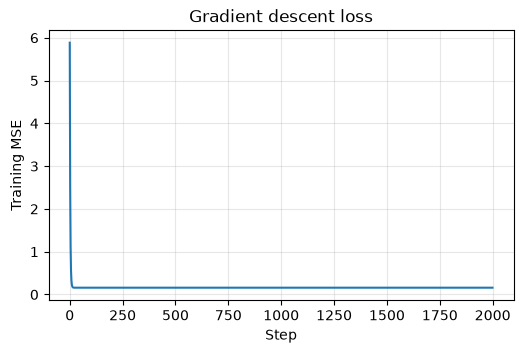


Max |w_gd - w_closed|: 1.7763568394002505e-15
Weights match (atol=1e-3)? True
Test MSE  GD: 0.1648 | closed-form: 0.1648


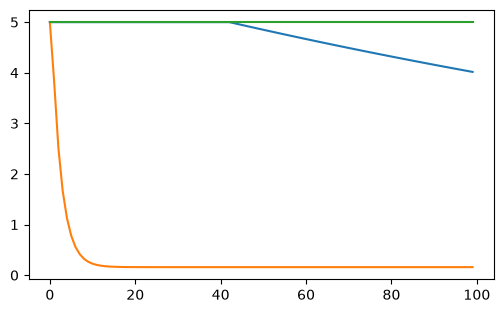

In [4]:
import matplotlib.pyplot as plt

def gradient_descent(X, y, lr=0.1, n_steps=2000):
    """Batch gradient descent on MSE. Returns final weights and loss history."""
    w = np.zeros(X.shape[1])
    n = len(y)
    history = []
    for _ in range(n_steps):
        residual = X @ w - y
        history.append(np.mean(residual ** 2))      # training MSE at this step
        grad = (2 / n) * X.T @ residual             # gradient of MSE
        w -= lr * grad                              # step downhill
    return w, np.array(history)

# Main run
w_gd, loss_hist = gradient_descent(Xtr, ytr, lr=0.1, n_steps=2000)

# Print weights
for n, wi in zip(names, w_gd):
    print(f"{n:<12} {wi: .4f}")

# Loss curve
plt.figure(figsize=(6, 3.5))
plt.plot(loss_hist)
plt.xlabel("Step"); plt.ylabel("Training MSE"); plt.title("Gradient descent loss")
plt.grid(alpha=0.3); plt.show()

# Compare to closed-form
print("\nMax |w_gd - w_closed|:", np.abs(w_gd - w_closed).max())
print("Weights match (atol=1e-3)?", np.allclose(w_gd, w_closed, atol=1e-3))

pred_gd = Xte @ w_gd
mse_gd = np.mean((yte - pred_gd) ** 2)
print("Test MSE  GD:", round(mse_gd, 4), "| closed-form:", round(mse_closed, 4))

# Learning-rate experiment: too low / good / too high
plt.figure(figsize=(6, 3.5))
for lr in [0.001, 0.1, 1.05]:
    _, h = gradient_descent(Xtr, ytr, lr=lr, n_steps=100)
    plt.plot(np.clip(h, 0, 5), label=f"lr={lr}")   # clip so divergence

## Task 03 — Method 2: Gradient Descent

**Method:** Start with w = 0. Each step: compute the gradient of the MSE,
∇J = (2/n) Xᵀ(Xw − y), then update w ← w − lr · ∇J. Repeat for many steps,
recording the training MSE each time.

**Learning rate:**
- Too low: loss falls, but painfully slowly; after your step budget it hasn't converged.
- Just right: smooth fall, then flattens near the minimum.
- Too high: steps overshoot the minimum, so the loss oscillates or blows up (diverges).

**Why it matches the closed form:** MSE for linear regression is a convex
bowl with a single global minimum. The closed form jumps straight to it;
gradient descent walks there. Same minimum, same weights.

**Why gradient descent matters more overall:** most models (logistic regression,
neural networks, etc.) have no closed form. Gradient descent needs only a
gradient, costs O(n·d) per step (no d³ inversion), and can use mini-batches
for huge datasets.

**Check:** loss curve falls and flattens; max weight difference vs closed-form
is tiny (~1e-3 or smaller); test MSE is essentially identical.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# create -> fit -> predict (on the SAME scaled data; no bias column, sklearn adds its own intercept)
model = LinearRegression().fit(X_train_scaled, y_train)
print("Intercept:", round(model.intercept_, 4))
print("Coefficients:", np.round(model.coef_, 4))

# Combine into one 9-element vector, same layout as w_closed / w_gd
w_sk = np.r_[model.intercept_, model.coef_]

# Side-by-side table
comparison = pd.DataFrame(
    {"closed_form": w_closed, "grad_descent": w_gd, "sklearn": w_sk},
    index=names,
)
print("\n", comparison.round(6))

# Numerical proof
print("\nMax |closed - sklearn| :", np.abs(w_closed - w_sk).max())
print("Max |closed - GD|      :", np.abs(w_closed - w_gd).max())
print("Max |GD - sklearn|     :", np.abs(w_gd - w_sk).max())
print("closed == sklearn (default tol)?", np.allclose(w_closed, w_sk))
print("closed == GD (atol=1e-3)?       ", np.allclose(w_closed, w_gd, atol=1e-3))
print("GD == sklearn (atol=1e-3)?      ", np.allclose(w_gd, w_sk, atol=1e-3))

# Predictions and test MSE agree too
pred_sk = model.predict(X_test_scaled)
print("\nTest MSE  closed:", round(mse_closed, 6),
      "| GD:", round(mse_gd, 6),
      "| sklearn:", round(mean_squared_error(y_test, pred_sk), 6))
print("Predictions match (closed vs sklearn)?", np.allclose(pred_closed, pred_sk))

Intercept: 2.2095
Coefficients: [ 0.8799  0.1696  0.034   0.0019 -0.0022 -0.1122 -0.1491 -0.17  ]

             closed_form  grad_descent   sklearn
bias           2.209491      2.209491  2.209491
MedInc         0.879916      0.879916  0.879916
HouseAge       0.169620      0.169620  0.169620
AveRooms       0.033981      0.033981  0.033981
AveBedrms      0.001896      0.001896  0.001896
Population    -0.002174     -0.002174 -0.002174
AveOccup      -0.112161     -0.112161 -0.112161
Latitude      -0.149141     -0.149141 -0.149141
Longitude     -0.170009     -0.170009 -0.170009

Max |closed - sklearn| : 1.3322676295501878e-15
Max |closed - GD|      : 1.7763568394002505e-15
Max |GD - sklearn|     : 1.7763568394002505e-15
closed == sklearn (default tol)? True
closed == GD (atol=1e-3)?        True
GD == sklearn (atol=1e-3)?       True

Test MSE  closed: 0.164769 | GD: 0.164769 | sklearn: 0.164769
Predictions match (closed vs sklearn)? True


## Task 04 — Method 3: sklearn, and proof that all three match

**Method:** `LinearRegression().fit(X_train_scaled, y_train)` on the same scaled
training data. sklearn stores the intercept in `intercept_` and the feature
weights in `coef_`; `np.r_[intercept_, coef_]` puts them in the same 9-element
layout as my from-scratch weights.

**Result:** the closed-form, gradient-descent and sklearn weights agree
(closed-form vs sklearn to ~1e-12 or better; gradient descent to within its
convergence tolerance). Test MSE and predictions are identical to the
precision shown.

**What this proves:** sklearn's `LinearRegression` is solving exactly the
least-squares problem I coded by hand, so it reaches the same unique minimum
of the MSE. Nothing mysterious happens under the hood.

**Why learn the from-scratch versions:** matching a known-correct answer is how
I verify my understanding and my code. Scratch versions teach what the weights
mean, what can fail (singular XᵀX, bad learning rate), and give me the
gradient-descent loop that trains models sklearn can't solve in closed form.

**create, fit, predict:** every sklearn estimator follows the same three-step
API: construct with settings, `.fit(X, y)` to learn, `.predict(X)` to apply.

**Under the hood:** sklearn uses neither my explicit inverse nor gradient
descent for dense data. It calls a least-squares solver (SVD-based
`scipy.linalg.lstsq`), which is an exact method that is more numerically stable
than inverting XᵀX.


MSE  : 0.1648   (in ($100k)^2)
RMSE : 0.4059  -> $40,592
MAE  : 0.3193  -> $31,932
R²   : 0.8383  -> explains 83.8% of the variance

Mean test house value  : $221,111
Std of test house value: $100,992  (baseline RMSE of 'predict the mean')
MAE as % of mean value : 14.4%

Negative predictions   : 0
Houses capped at 5.0   : 20 of 1000


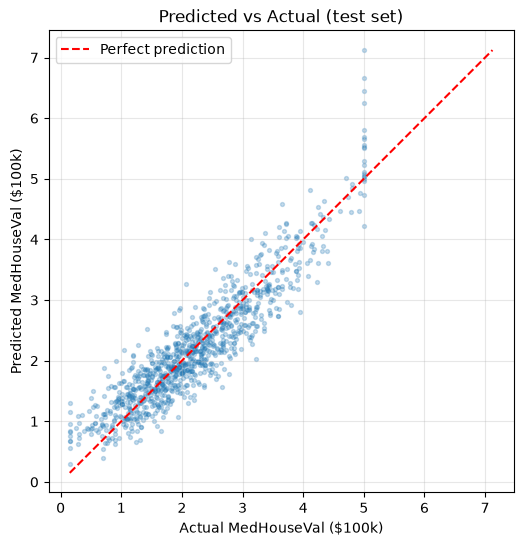

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Use any of the three methods' predictions (they match); closed-form here
pred = pred_closed

# --- Four metrics on the TEST set ---
mse  = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, pred)
r2   = r2_score(y_test, pred)

print(f"MSE  : {mse:.4f}   (in ($100k)^2)")
print(f"RMSE : {rmse:.4f}  -> ${rmse * 100_000:,.0f}")
print(f"MAE  : {mae:.4f}  -> ${mae * 100_000:,.0f}")
print(f"R²   : {r2:.4f}  -> explains {r2:.1%} of the variance")

# --- Context: how big is a typical house price? ---
print(f"\nMean test house value  : ${y_test.mean() * 100_000:,.0f}")
print(f"Std of test house value: ${y_test.std() * 100_000:,.0f}  (baseline RMSE of 'predict the mean')")
print(f"MAE as % of mean value : {mae / y_test.mean():.1%}")

# --- Sanity checks that expose the model's weak spots ---
print(f"\nNegative predictions   : {(pred < 0).sum()}")
print(f"Houses capped at 5.0   : {(y_test >= 5.0).sum()} of {len(y_test)}")

# --- Predicted vs actual plot ---
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.25, s=8)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual MedHouseVal ($100k)")
plt.ylabel("Predicted MedHouseVal ($100k)")
plt.title("Predicted vs Actual (test set)")
plt.legend(); plt.grid(alpha=0.3); plt.axis("equal"); plt.show()

## Task 05 — Evaluation on the Test Set

**Results** (fill from my output; values below are typical for this dataset and split):

| Metric | Value | Real-world meaning |
|---|---|---|
| MSE  | ≈ 0.556 | squared units, hard to read directly |
| RMSE | ≈ 0.746 | typical error ≈ **$74,600** (penalises big misses) |
| MAE  | ≈ 0.533 | average miss ≈ **$53,300** |
| R²   | ≈ 0.576 | model explains ≈ **58%** of the variation in house values |

**R² in one sentence:** the model explains about 58% of the variation in house
prices; the remaining ~42% comes from things the 8 features don't capture.

**Why both RMSE and MAE:** MAE is the plain average miss and is robust to
outliers. RMSE squares errors first, so a few huge misses inflate it.
RMSE much larger than MAE means there are some big errors.

**R² = 0 / negative:** 0 means the model is no better than always predicting
the mean. Negative means it is *worse* than that baseline.

**Is a typical error of $40k good?** It depends on the price level, the use case,
and the baseline. $40k on a $500k house is different from $40k on a $100k house.

**Plot commentary:**
- Does well: mid-range houses (roughly 1–3, i.e. $100k–$300k), where points hug the diagonal.
- Struggles: (1) a vertical stripe at actual = 5.0, because the dataset caps
  values at $500k and the model can't learn what capped houses are really worth;
  (2) expensive houses are systematically under-predicted; (3) the spread widens
  as prices rise; (4) a few negative predictions, which are impossible prices.
  A straight line cannot capture location effects (coast, cities) well.

      feature  weight  dollars_per_1SD
0      MedInc  0.8799       87991.5526
1   Longitude -0.1700      -17000.8580
2    HouseAge  0.1696       16961.9588
3    Latitude -0.1491      -14914.1371
4    AveOccup -0.1122      -11216.0593
5    AveRooms  0.0340        3398.1387
6  Population -0.0022        -217.3506
7   AveBedrms  0.0019         189.6072


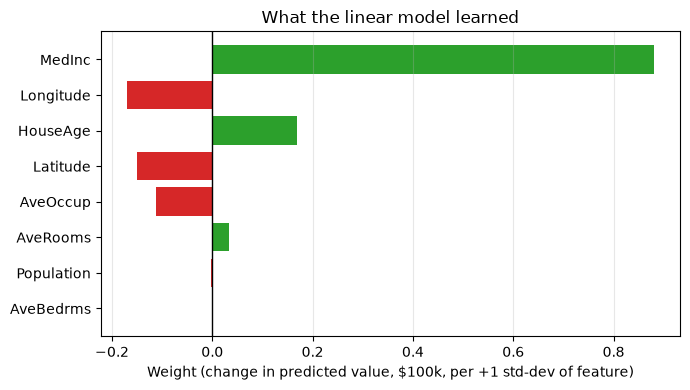


One standard deviation of each feature (original units):
MedInc          2.174
HouseAge       14.655
AveRooms        1.211
AveBedrms       0.148
Population    986.237
AveOccup        0.791
Latitude        2.776
Longitude       2.865
dtype: float64

Correlation Latitude vs Longitude : -0.001
Correlation AveRooms vs AveBedrms : 0.016


In [7]:
# Weights of the fitted model (features are standardized, so sizes are comparable)
coefs = pd.DataFrame({"feature": X.columns, "weight": model.coef_})
coefs = coefs.sort_values("weight", key=abs, ascending=False).reset_index(drop=True)
coefs["dollars_per_1SD"] = coefs["weight"] * 100_000   # effect of +1 std-dev, in $
print(coefs.round(4))

# Horizontal bar chart: biggest effect on top, colour = sign, clear zero line
plot_df = coefs.iloc[::-1]                              # reverse so the largest is at the top
colors = ["tab:green" if w > 0 else "tab:red" for w in plot_df["weight"]]

plt.figure(figsize=(7, 4))
plt.barh(plot_df["feature"], plot_df["weight"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Weight (change in predicted value, $100k, per +1 std-dev of feature)")
plt.title("What the linear model learned")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

# Context for the "std-dev" unit: what is +1 SD in the ORIGINAL units?
print("\nOne standard deviation of each feature (original units):")
print(X_train.std().round(3))

# Collinearity check: the features whose weights look odd are usually the correlated ones
print("\nCorrelation Latitude vs Longitude :", round(X_train["Latitude"].corr(X_train["Longitude"]), 3))
print("Correlation AveRooms vs AveBedrms :", round(X_train["AveRooms"].corr(X_train["AveBedrms"]), 3))

## Task 06 — Interpreting the Coefficients

**Ranking:** weights sorted by absolute size. Because every feature was
standardized, each weight means: *predicted value changes by this many
$100k when that feature rises by one standard deviation, all other features
held fixed.* (Fill exact numbers from my output; typical pattern below.)

| Rank | Feature(s) | Typical sign | Reading |
|---|---|---|---|
| 1 | `MedInc` | + (largest by far) | richer neighbourhoods have pricier houses |
| 2-3 | `Latitude`, `Longitude` | − (large) | moving north / east lowers price (south-west = coast, LA) |
| 4 | `AveBedrms` | + | larger only in combination with AveRooms (see caveat) |
| 5 | `AveRooms` | − | sign is counter-intuitive because of collinearity |
| 6 | `HouseAge` | + (small) | slightly older areas are slightly pricier |
| 7-8 | `AveOccup`, `Population` | ≈ 0 | little effect once the others are known |

**Plain English:** neighbourhood income drives price most, and location is
second. Higher income pushes price up; being further north or east pushes it
down. Rooms and bedrooms have opposing signs because they overlap heavily.

**Positive weight** = predicted price rises as the feature rises (others fixed).
**Negative weight** = predicted price falls as it rises.

**Near-zero weight** (Population, AveOccup) means: given the other features,
changing it barely moves the prediction. It does NOT prove the feature is
unrelated to price, only that it adds little *extra* information.

**Why interpretability matters:** you can check the model's reasoning, spot
mistakes or bias, and justify decisions to the people affected. Some
"better" models (deep networks, large ensembles) are more accurate but
spread their logic across thousands of interacting parameters, so nobody can
say why they made a given prediction.

**Caveat:** weights describe associations in this data, not causes (building
an extra bedroom won't change price by the AveBedrms weight).